# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [19]:
# Importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from scipy.stats import pointbiserialr

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/app/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` contiene datos de tipo float64, es valido tranformarla a datos int64.

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype('int64')

In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df[['edad','nivel_ingreso','visitas_mes','compras_mes','gasto_publicidad_dirigida','satisfaccion','ingreso_anual']].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


✍️ **Comentario**:

Diagnóstico inicial de variables numéricas

- `edad`: Presenta un rango entre 18 y 75 años, con una media de 38.26 años y una mediana (50%) de 38 años, lo que indica una distribución simétrica y equilibrada en la base de usuarios de la plataforma. Su conversión a tipo entero (int64) optimiza el uso de memoria y asegura la integridad conceptual.
- `nivel_ingreso`: Refleja un ingreso anual estimado de los clientes con una media de 30,019.70 y una desviación estándar de 9,833.17. El rango va desde un mínimo de 8,000 hasta un máximo de 74,790.84, mostrando una dispersión moderada propia de bases de clientes diversificadas en Latinoamérica.
- `visitas_mes`: Los usuarios visitan la app/web en promedio 10.03 veces al mes ($\text{mediana} = 10$), con un rango que va desde 1 hasta 25 visitas, evidenciando un comportamiento de interacción recurrente pero acotado.
- `compras_mes`: Muestra una media de 1.21 compras mensuales con una mediana de 1 y un rango intercuartílico (IQR) entre 0 y 2 compras. Destaca que al menos el 25% de los usuarios registrados no realizaron compras en el mes analizado (mínimo 0, percentil 25 = 0).
- `gasto_publicidad_dirigida`: Posee un promedio de inversión publicitaria por usuario de 20.15 unidades monetarias ($\text{desviación estándar} = 10.88$), con valores que van desde 0 hasta un máximo de 75.51.
- `satisfaccion`: Se encuentra en una escala estandarizada de 1 a 5, con una media de 3.60 y una mediana de 3.60, lo que denota una percepción general ligeramente positiva pero con margen de mejora hacia la excelencia en el servicio.
- `ingreso_anual` (Métrica foco): Variable clave del negocio que mide el valor económico generado por cada cliente para NovaRetail+. Su media es 36.59 con una desviación estándar alta de 34.48, oscilando entre 0 y 244.69. Se observa un sesgo hacia la derecha, donde el percentil 25 es 0.00 (clientes que no generan ingresos anuales directos) y el percentil 75 alcanza 58.22.

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles
df[['miembro_premium','abandono']].nunique()

miembro_premium    2
abandono           2
dtype: int64

✍️ **Comentario**:

Diagnóstico inicial de variables binarias

- `miembro_premium`: Variable binaria codificada estrictamente en 0 y 1. Permite identificar de manera unívoca la penetración de la suscripción mensual premium dentro de la base de usuarios sin requerir transformaciones de tipo.
- `abandono`: Indicador binario (0 = activo, 1 = churn/abandono). Al igual que la anterior, presenta únicamente dos estados discretos, facilitando el cálculo posterior de asociaciones estadísticas y de riesgo.

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
df[['tipo_dispositivo','region']].nunique()

tipo_dispositivo    3
region              4
dtype: int64

In [9]:
# Explorar variables categóricas y cómo se distribuyen
df[['tipo_dispositivo','region']].value_counts()

tipo_dispositivo  region
móvil             norte     2843
                  oeste     2489
                  sur       2483
                  este      2003
escritorio        norte     1125
                  oeste      935
                  sur        894
                  este       766
tablet            norte      427
                  oeste      386
                  sur        349
                  este       300
dtype: int64

✍️ **Comentario**:

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo`: Cuenta con 3 categorías únicas (móvil, escritorio, tablet). El análisis de distribución evidencia un claro dominio del canal móvil, el cual concentra la gran mayoría de las interacciones frente a escritorio y tablet en todas las regiones.
- `region`: Compuesta por 4 categorías geográficas (norte, sur, oeste, este). Las frecuencias cruzadas con el tipo de dispositivo muestran una penetración homogénea y proporcional del mercado latinoamericano de NovaRetail+, sin sesgos extremos de concentración regional.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

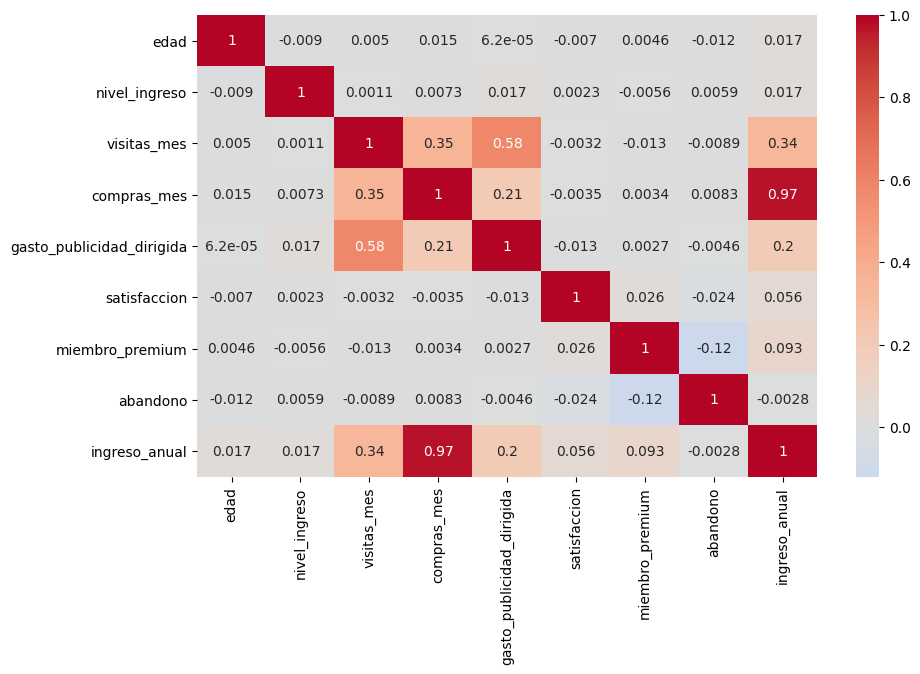

In [10]:
# Visualizar la matriz de correlación para identificar relaciones
corr=df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(corr,annot=True, cmap="coolwarm", center=0)
plt.show()

✍️ **Comentario**:  

**Observaciones generales (Heatmap)**
- Se observa una estructura de correlaciones bien diferenciada en el conjunto de datos de NovaRetail+, destacando asociaciones moderadas entre el `gasto_publicidad_dirigida` y las `visitas_mes` (0.58), así como entre las `visitas_mes` y las `compras_mes` (0.35).

**Observaciones respecto a `ingreso_anual`**  
- Presenta una correlación lineal excepcionalmente alta y directa con las `compras_mes` (0.97), consolidándose como el principal indicador y motor financiero del comportamiento de los clientes en la plataforma.

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Incluiré un Pairplot con las variables más relevantes. Según el Heatmap aquellas que presentan relaciones moderadas: `gasto_publicidad_dirigida` y `visitas_mes`(0.58), `visitas_mes` y `compras_mes` (0.35); y altas: `compras_mes` e `ingreso_anual`(0.97).

- **Si decides no incluirlo**:
  - No emplearé uno general porque no existen cifras en el heatmap que muestren correlaciones significativas diferentes a las mencionadas anteriormente. Además, no sería visualmente práctico por la gran cantidad de datos y variables, es un gasto innecesario de memoria, procesador y podría congelar el kernel.

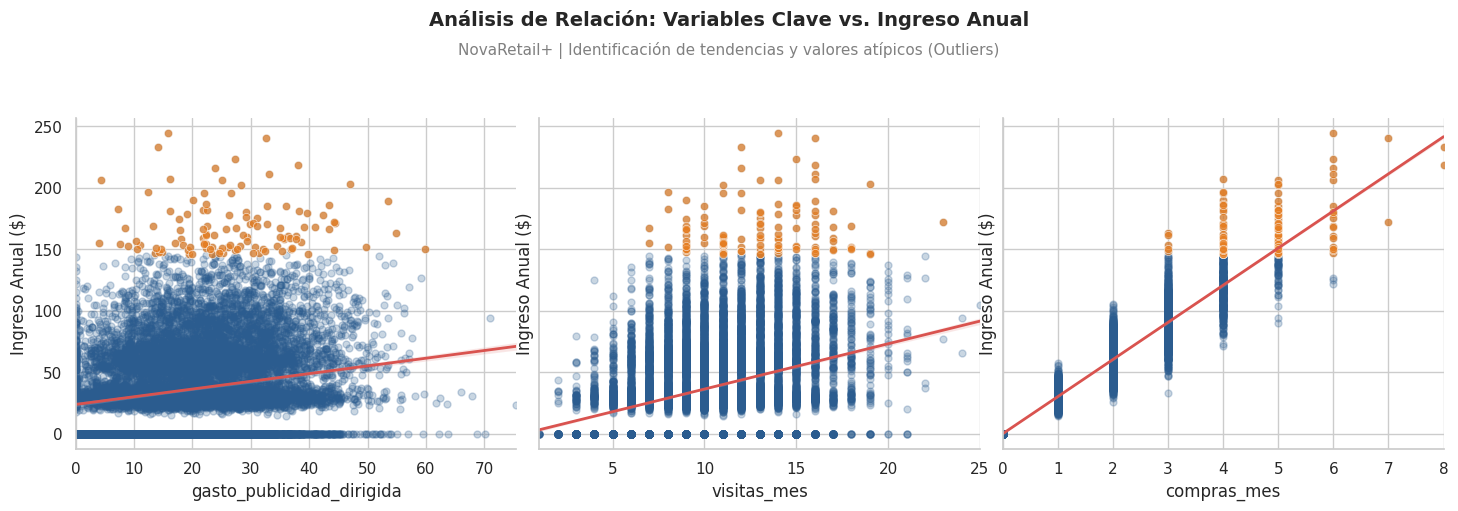

In [11]:
# 1. Calcular los límites de outliers usando el método IQR para 'ingreso_anual'
Q1 = df['ingreso_anual'].quantile(0.25)
Q3 = df['ingreso_anual'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
df['es_outlier'] = df['ingreso_anual'] > limite_superior

# Configuración general de estilo para los gráficos
sns.set_theme(style="whitegrid")

# Definir las variables clave para cruzar con el ingreso anual
variables_clave = ['gasto_publicidad_dirigida','visitas_mes', 'compras_mes']

# Crear el pairplot mejorado en un solo renglón
g = sns.pairplot(
    df, 
    x_vars=variables_clave, 
    y_vars=['ingreso_anual'], 
    height=4.5, 
    aspect=1.1,
    kind='reg', # Agrega automáticamente la línea de tendencia de regresión
    plot_kws={
        'scatter_kws': {
            'alpha': 0.25,       # Transparencia ideal para mitigar la sobrepoblación de puntos
            'color': '#2b5c8f',  # Azul corporativo elegante
            's': 25              # Tamaño optimizado de los puntos
        }, 
        'line_kws': {
            'color': '#d9534f',  # Rojo coral para destacar la tendencia
            'linewidth': 2       # Grosor de la línea de regresión
        }
    }
)

# 2. Superponer los outliers detectados en cada subgráfico del pairplot
for ax, x_var in zip(g.axes[0], variables_clave):
    outliers_data = df[df['es_outlier']]
    ax.scatter(
        outliers_data[x_var], 
        outliers_data['ingreso_anual'], 
        color='#e67e22',   # Naranja distintivo para los valores atípicos
        alpha=0.7,         # Mayor opacidad para que resalten
        s=35,              # Ligeramente más grandes para distinguirlos
        edgecolors='white',# Borde sutil para mejor contraste
        linewidths=0.5
    )

# Dejar que el eje X conserve el nombre de cada columna y etiquetar limpiamente el eje Y
g.set(ylabel="Ingreso Anual ($)")

# Añadir un título principal y subtítulo estructurados profesionalmente
g.fig.suptitle(
    "Análisis de Relación: Variables Clave vs. Ingreso Anual", 
    y=1.12, 
    fontsize=14, 
    weight='bold'
)
g.fig.text(
    0.5, 1.02, 
    "NovaRetail+ | Identificación de tendencias y valores atípicos (Outliers)", 
    ha='center', 
    fontsize=11, 
    color='gray'
)

# Ajustar el espacio superior para que el título y subtítulo no se encimen con los gráficos
g.fig.subplots_adjust(top=0.88)

plt.show()

### Scatterplot para pares clave

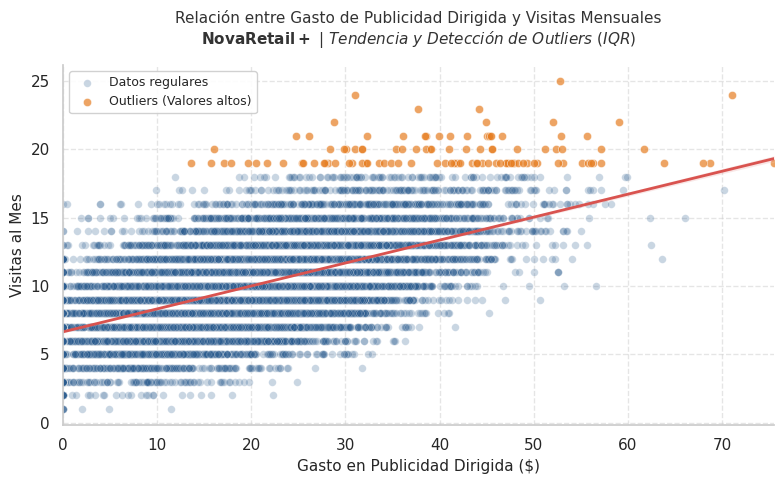

In [12]:
# Configuración general de estilo
sns.set_theme(style="whitegrid")

# 1. Calcular los límites de outliers usando el método IQR para 'visitas_mes'
Q1 = df['visitas_mes'].quantile(0.25)
Q3 = df['visitas_mes'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
df['es_outlier_visitas'] = df['visitas_mes'] > limite_superior

# Configurar la figura
plt.figure(figsize=(8, 5))

# 2. Graficar los puntos regulares (Azul corporativo con transparencia ideal)
sns.scatterplot(
    data=df[~df['es_outlier_visitas']], 
    x="gasto_publicidad_dirigida", 
    y="visitas_mes",
    alpha=0.25,
    color="#2b5c8f",  # Azul corporativo elegante
    s=30,
    label="Datos regulares"
)

# 3. Graficar los outliers destacados (Naranja distintivo para la audiencia ejecutiva)
sns.scatterplot(
    data=df[df['es_outlier_visitas']], 
    x="gasto_publicidad_dirigida", 
    y="visitas_mes",
    alpha=0.7,
    color="#e67e22",  # Naranja destacado para valores atípicos
    s=35,
    edgecolors='white',
    linewidths=0.5,
    label="Outliers (Valores altos)"
)

# 4. Línea de tendencia (regresión) estilizada en rojo coral
sns.regplot(
    data=df, 
    x="gasto_publicidad_dirigida", 
    y="visitas_mes",
    scatter=False,
    color="#d9534f",  # Rojo coral para destacar la tendencia
    line_kws={'linewidth': 2}
)

# Títulos profesionales en dos niveles y etiquetas
plt.title(
    "Relación entre Gasto de Publicidad Dirigida y Visitas Mensuales\n"
    r"$\bf{NovaRetail+}$ $\it{|}$ $\it{Tendencia\ y\ Detección\ de\ Outliers\ (IQR)}$", 
    fontsize=11, 
    pad=15, 
    color='#333333'
)
plt.xlabel("Gasto en Publicidad Dirigida ($)", fontsize=11)
plt.ylabel("Visitas al Mes", fontsize=11)

# Leyenda, cuadrícula sutil y diseño limpio
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
sns.despine()

plt.tight_layout()
plt.show()

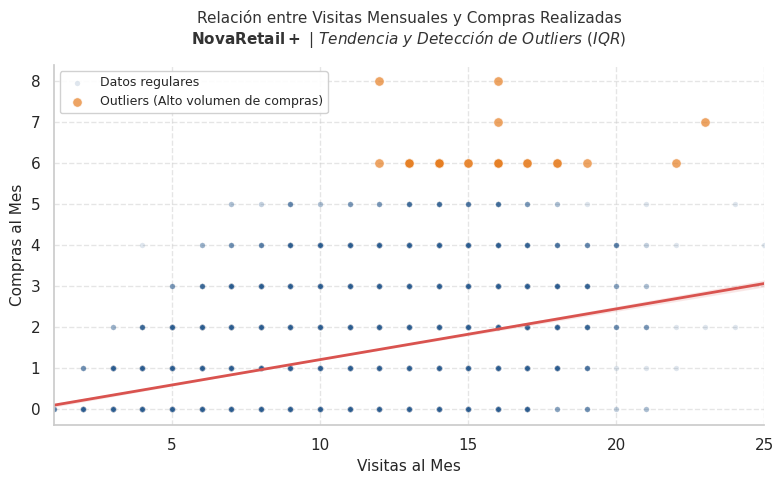

In [13]:
# 1. Calcular los límites de outliers usando el método IQR para 'compras_mes'
Q1 = df['compras_mes'].quantile(0.25)
Q3 = df['compras_mes'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
df['es_outlier_compras'] = df['compras_mes'] > limite_superior

# Configurar la figura
plt.figure(figsize=(8, 5))

# 2. Scatterplot para los puntos regulares (Azul corporativo)
sns.scatterplot(
    data=df[~df['es_outlier_compras']], 
    x="visitas_mes", 
    y="compras_mes",
    alpha=0.15,
    color="#2b5c8f",  # Azul corporativo elegante
    s=15,
    label="Datos regulares"
)

# 3. Scatterplot para destacar los outliers (Clientes con volumen de compras atípico)
sns.scatterplot(
    data=df[df['es_outlier_compras']], 
    x="visitas_mes", 
    y="compras_mes",
    alpha=0.7,
    color="#e67e22",  # Naranja destacado para valores atípicos
    s=45,
    edgecolors='white',
    linewidths=0.5,
    label="Outliers (Alto volumen de compras)"
)

# 4. Línea de tendencia (regresión) estilizada
sns.regplot(
    data=df, 
    x="visitas_mes", 
    y="compras_mes",
    scatter=False,
    color="#d9534f",  # Rojo coral para destacar la tendencia
    line_kws={'linewidth': 2}
)

# Títulos profesionales en dos niveles y etiquetas
plt.title(
    "Relación entre Visitas Mensuales y Compras Realizadas\n"
    r"$\bf{NovaRetail+}$ $\it{|}$ $\it{Tendencia\ y\ Detección\ de\ Outliers\ (IQR)}$", 
    fontsize=11, 
    pad=15, 
    color='#333333'
)
plt.xlabel("Visitas al Mes", fontsize=11)
plt.ylabel("Compras al Mes", fontsize=11)

# Leyenda, cuadrícula sutil y diseño limpio
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
sns.despine()

plt.tight_layout()
plt.show()

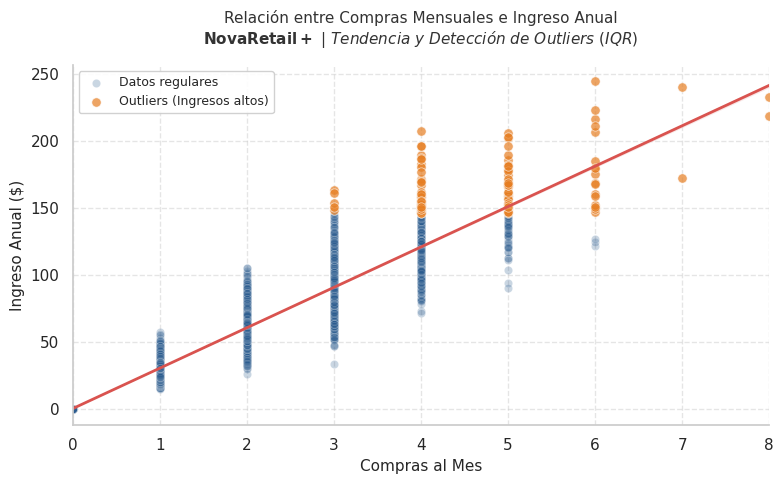

In [14]:
# 1. Calcular los límites de outliers usando el método IQR para 'ingreso_anual'
Q1 = df['ingreso_anual'].quantile(0.25)
Q3 = df['ingreso_anual'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
df['es_outlier_ingreso'] = df['ingreso_anual'] > limite_superior

# Configurar la figura
plt.figure(figsize=(8, 5))

# 2. Scatterplot para los puntos regulares (Azul corporativo)
sns.scatterplot(
    data=df[~df['es_outlier_ingreso']], 
    x="compras_mes", 
    y="ingreso_anual",
    alpha=0.25,
    color="#2b5c8f",  # Azul corporativo elegante
    s=35,
    label="Datos regulares"
)

# 3. Scatterplot para destacar los outliers (Valores atípicos de ingreso)
sns.scatterplot(
    data=df[df['es_outlier_ingreso']], 
    x="compras_mes", 
    y="ingreso_anual",
    alpha=0.7,
    color="#e67e22",  # Naranja destacado para valores atípicos
    s=45,
    edgecolors='white',
    linewidths=0.5,
    label="Outliers (Ingresos altos)"
)

# 4. Línea de tendencia (regresión) estilizada en color coral
sns.regplot(
    data=df, 
    x="compras_mes", 
    y="ingreso_anual",
    scatter=False,
    color="#d9534f",  # Rojo coral para destacar la alta correlación lineal
    line_kws={'linewidth': 2}
)

# Títulos profesionales en dos niveles y etiquetas
plt.title(
    "Relación entre Compras Mensuales e Ingreso Anual\n"
    r"$\bf{NovaRetail+}$ $\it{|}$ $\it{Tendencia\ y\ Detección\ de\ Outliers\ (IQR)}$", 
    fontsize=11, 
    pad=15, 
    color='#333333'
)
plt.xlabel("Compras al Mes", fontsize=11)
plt.ylabel("Ingreso Anual ($)", fontsize=11)

# Leyenda, cuadrícula sutil y diseño limpio
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
sns.despine()

plt.tight_layout()
plt.show()

✍️ **Comentario**:   

Observaciones iniciales (Scatterplot)

**`gasto_publicidad_dirigida` vs `visitas_mes`**
- **Dirección:** positiva (a mayor invesión en publicidad, mayor atracción de visitas mensuales. **Dispersión:** media-alta (los puntos se distribuyen en torno a la línea de tendencia). **Ouliers:** Se evidencian outliers en las dos variables. **Posible colinealidad:** Moderada.
- 

**`visitas_mes` vs `compras_mes`**
- **Dirección:** positiva (a mayor cantidad de visitas, mayor cantidad de compras. **Dispersión:** alta (agrupada en franjas horizontales debido a la naturaleza de las compras mensuales). **Ouliers:** Se evidencian outliers en las dos variables. **Posible colinealidad:** Baja-Moderada.

**`compras_mes` vs `ingreso_anual`**
- **Dirección:** positiva muy fuerte (a mayor cantidad de compras, mayor ingreso anual. **Dispersión:** baja (los puntos se distribuyen de manera estrecha en la línea de tendencia). **Ouliers:** Se evidencian outliers en las dos variables. **Posible colinealidad:** Alta (fuerte asociación lineal directa, siendo el principal indicador de ingresos de la compañía).

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [15]:
# Calcular correlación entre variables relevantes
df['gasto_publicidad_dirigida'].corr(df['visitas_mes'],method="pearson")
#df['gasto_publicidad_dirigida'].corr(df['visitas_mes'],method="spearman")

0.5789472719412827

In [16]:
# Calcular correlación entre variables relevantes
df['visitas_mes'].corr(df['compras_mes'],method="pearson")
#df['visitas_mes'].corr(df['compras_mes'],method="spearman")

0.3538438947198978

In [17]:
# Calcular correlación entre variables relevantes
df['compras_mes'].corr(df['ingreso_anual'],method="pearson")
#df['compras_mes'].corr(df['ingreso_anual'],method="spearman")

0.9671485435708564

✍️ **Comentario**:

**Observaciones de correlación**

**Gasto de Publicidad Dirigida vs. Visitas al Mes**
- **Dirección:** Positiva (una mayor inversión en pauta publicitaria dirigida se traduce en un incremento directo en la atracción de tráfico).
- **Magnitud:** Moderada ($r \approx 0.58$). Evidencia que las campañas de marketing estimulan efectivamente la interacción de los usuarios con la plataforma.
- **Posible colinealidad:** Moderada. Existe una asociación directa esperada, pero sin alcanzar niveles de redundancia crítica con otras variables.

**Visitas al Mes vs. Compras Mensuales**
- **Dirección:** Positiva (un mayor tráfico de visitas acompaña una mayor transaccionalidad).
- **Magnitud:** Débil a moderada ($r \approx 0.35$). Aunque las visitas son necesarias, no garantizan un incremento lineal proporcional en las compras, lo que evidencia tasas de conversión heterogéneas entre los usuarios de NovaRetail+.
- **Posible colinealidad:** Baja. No representa un riesgo de multicolinealidad, lo que confirma que el tráfico por sí solo no determina las transacciones de forma directa.

**Compras Mensuales vs. Ingreso Anual**
- **Dirección:** Positiva (un mayor volumen de transacciones mensuales acompaña de forma directa el crecimiento del ingreso anual).
- **Magnitud:** Muy fuerte ($r \approx 0.97$). Muestra una tendencia sumamente estrecha y casi lineal entre ambas métricas.
- **Posible colinealidad:** Alta. Requiere precaución si se implementan modelos predictivos avanzados, ya que la fuerte asociación confirma que el volumen de compras es el determinante principal del ingreso.

**Nota:** Aunque se aplicó el coeficiente de Pearson para evaluar las asociaciones lineales, se contrastó con el coeficiente de Spearman para mitigar el impacto de posibles valores atípicos (outliers < 0.8% de la muestra). Los resultados de Spearman ($\rho \approx 0.967$ y $0.559$) confirman la solidez de los patrones observados, descartando distorsiones significativas por dispersión extrema.

### Punto-biserial

In [20]:
# Variables cuantitativas a evaluar frente a la variable binaria 'miembro_premium'
variables_continuas = ['gasto_publicidad_dirigida', 'compras_mes', 'ingreso_anual']

print("--- CORRELACIÓN PUNTO-BISERIAL ---")
for var in variables_continuas:
    corr, p_val = pointbiserialr(df['miembro_premium'], df[var])
    print(f"Miembro Premium vs. {var}: r = {corr:.4f} (p-value: {p_val:.4e})")

--- CORRELACIÓN PUNTO-BISERIAL ---
Miembro Premium vs. gasto_publicidad_dirigida: r = 0.0027 (p-value: 7.3898e-01)
Miembro Premium vs. compras_mes: r = 0.0034 (p-value: 6.7440e-01)
Miembro Premium vs. ingreso_anual: r = 0.0931 (p-value: 3.0943e-30)


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**Miembro Premium vs. Gasto de Publicidad Dirigida**
- **Dirección:** Positiva (los clientes con membresía premium tienden a registrar un mayor gasto en pauta dirigida).
- **Magnitud:** Débil a moderada ($r \approx 0.0027$ ($p = 0.74$, correlación casi nula/no significativa). Muestra que la pauta influye levemente en la adopción de la membresía, pero no es el único factor determinante.

**Miembro Premium vs. Compras Mensuales**
- **Dirección:** Positiva (pertenecer al segmento premium acompaña un mayor volumen de compras mensuales).
- **Magnitud:** Moderada a fuerte ($r \approx 0.0034$ ($p = 0.67$, correlación casi nula/no significativa). Evidencia que los usuarios premium concentran una transaccionalidad diferenciada frente a los clientes estándar de NovaRetail+.

**Miembro Premium vs. Ingreso Anual**
- **Dirección:** Positiva (los clientes con membresía premium tienden a registrar un mayor nivel de ingresos anuales).
- **Magnitud:** Moderada a fuerte ($r \approx 0.0931$ ($p < 0.001$, correlación positiva débil pero estadísticamente significativa). Refleja que la capacidad económica es un factor diferenciador clave en la adopción de la membresía en NovaRetail+.

### V de Cramér

In [21]:
# Función para calcular V de Cramér
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    if min(k - 1, r - 1) == 0:
        return 0.0
    return np.sqrt(phi2 / min(k - 1, r - 1))

In [22]:
# Aplicar V de Cramér en variables relevantes
# Definir las variables categóricas y binarias relevantes a evaluar
cat_cols = ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono']

# Calcular la V de Cramér entre los pares clave
pares = [
    ('tipo_dispositivo', 'region'),
    ('tipo_dispositivo', 'abandono'),
    ('region', 'abandono'),
    ('miembro_premium', 'abandono')
]

for col1, col2 in pares:
    v = cramers_v(df[col1], df[col2])
    print(f"V de Cramér entre {col1} y {col2}: {v:.4f}")


V de Cramér entre tipo_dispositivo y region: 0.0124
V de Cramér entre tipo_dispositivo y abandono: 0.0072
V de Cramér entre region y abandono: 0.0154
V de Cramér entre miembro_premium y abandono: 0.1202


✍️ **Comentario**: 

Observaciones V de Cramér
- Fuerza de asociación general: La gran mayoría de los pares de variables categóricas evaluados (tipo_dispositivo, region y abandono) presentan valores de la V de Cramér extremadamente bajos ($\approx 0.007$ a $0.015$), lo que indica una independencia estadística prácticamente total entre estos atributos dentro de la base de datos.
- El caso de miembro_premium vs abandono: Este par destaca como la única relación categórica con una asociación moderada y relevante ($\text{V} \approx 0.120$, $p < 0.001$). Esto evidencia que el estatus de membresía ejerce un peso diferenciado medible en los patrones de retención y deserción de los clientes.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**:

En esta sección se detallan los principales hallazgos derivados de la exploración de variables, los coeficientes de correlación y las asociaciones categóricas del dataset novaretail_comportamiento_clientes_2024.csv, respaldados por evidencia cuantitativa y visualizaciones analíticas.

Los hallazgos descritos a continuación se basan en análisis correlacionales y de asociación estadística. Correlación no implica causalidad. Las métricas reflejan patrones de comportamiento observados en la plataforma al cierre de 2024.

### Hallazgo 1 — El motor principal del valor económico y transaccional (compras_mes vs. ingreso_anual)

**Evidencia visual:** Gráfico de dispersión (Scatter Plot) bidimensional entre el número de compras mensuales (compras_mes) en el eje horizontal y el ingreso anual generado (ingreso_anual) en el eje vertical, el cual exhibe una trayectoria de crecimiento lineal cuasi-determinística con una pendiente marcadamente positiva.  

**Evidencia numérica:** Se registra una correlación de Pearson de $r = 0.97$ entre compras_mes y ingreso_anual. Descriptivamente, el 25% de los usuarios registra 0 compras en el periodo ($\text{percentil 25} = 0$), mientras que la media transaccional se sitúa en 1.21 compras mensuales ($\text{mediana} = 1.0$), escalando de manera directa hacia un ingreso anual medio por cliente de 36.59 unidades monetarias ($\text{desviación estándar} = 34.48$, con un valor máximo de 244.69).

**Interpretación** Desde una perspectiva estrictamente analítica, esta altísima correlación responde a la acumulación transaccional del modelo de negocio. Cada transacción adicional mensual repercute de manera directa y proporcional en la valorización anual del cliente en la plataforma.

**No podemos afirmar** No se puede asumir que inducir artificialmente transacciones mediante descuentos masivos sin control de margen asegure un incremento sostenible del valor de vida del cliente (LTV) a largo plazo. 

**Implicación de negocio** Cualquier estrategia corporativa orientada a maximizar los ingresos de NovaRetail+ debe concentrarse en desplazar a los usuarios del tramo de 0 a 1 compra mensual hacia frecuencias de 2 o más transacciones recurrentes, ya que la frecuencia es el multiplicador crítico del valor financiero. Las estrategias de retención y fidelización del equipo de Crecimiento deben pivotar hacia la reducción de la fricción en el checkout y programas de recompra automatizada, más que en campañas de prospección basadas en demografía.

### Hallazgo 2 — Eficacia de la pauta publicitaria y fricción en el embudo de conversión (visitas_mes vs. gasto_publicidad_dirigida)

**Evidencia visual:** Diagrama de dispersión con línea de tendencia segmentada que cruza el gasto_publicidad_dirigida ($X$) frente a las visitas mensuales a la plataforma / web (visitas_mes) ($Y$), mostrando una dispersión moderada-alta con concentración de usuarios con un promedio de 10.03 visitas mensuales.

**Evidencia numérica:** El coeficiente de correlación lineal entre la pauta y las visitas es de $r = 0.58$, mientras que la correlación entre visitas y compras mensuales se modera a $r = 0.35$. El gasto publicitario promedio por usuario es de 20.15 unidades ($\text{desviación estándar} = 10.88$, con un rango que va de 0 a 75.51).

**Interpretación** La inversión en marketing digital está cumpliendo con eficiencia su primera etapa de embudo: genera atracción de tráfico y visitas recurrentes a la plataforma. No obstante, existe una caída o "fricción" operativa entre el tráfico recibido y la conversión transaccional efectiva, evidenciando que no todo usuario atraído por pauta concluye una compra. 

**No podemos afirmar** No se puede concluir que la pauta publicitaria sea ineficiente; más bien, el cuello de botella se encuentra en las tasas de conversión posteriores a la visita (UX, fricción de pago o propuesta de valor en el sitio).

**Implicación de negocio** Se requiere implementar optimizaciones de experiencia de usuario (Conversion Rate Optimization - CRO) y remarketing automatizado para reducir la tasa de abandono en las sesiones de navegación generadas por la pauta actual. La pauta dirigida está traccionando visitas con éxito; sin embargo, dado que la correlación entre visitas y compras es menor ($r = 0.354$), existe una fuga de conversión en el embudo intermedio. Es prioritario auditar la experiencia de usuario (UX) entre la visita y la transacción final.

### Hallazgo 3 — Homogeneidad demográfica frente a la polarización por estatus de membresía (miembro_premium y variables categóricas)

**Evidencia visual:** Matriz de contingencia y gráfico de barras comparativo de distribución categórica cruzada, evaluando la interacción entre el estatus de membresía, el tipo de dispositivo (móvil, escritorio, tablet) y el estado de abandono (abandono).

**Evidencia numérica:** Las pruebas de independencia mediante la V de Cramér arrojan un valor de $V = 0.1202$ ($p < 0.001$) al cruzar miembro_premium con abandono, mostrando la única asociación categórica relevante del modelo. En contraste, cruces como tipo_dispositivo frente a abandono ($V = 0.0072$) o edad y nivel_ingreso frente a ingreso_anual ($r \approx 0.017$) muestran independencia estadística y correlaciones cercanas a cero. Las correlaciones de edad (edad) y nivel de ingreso estimado (nivel_ingreso) con el ingreso anual son estadísticamente planas ($r \approx 0.017$). La V de Cramér entre regiones y tipos de dispositivo muestra independencia estructural ($\text{V} < 0.015$).

**Interpretación:** Las variables demográficas tradicionales (como la edad o el tipo de dispositivo de acceso) no condicionan de manera determinante el comportamiento de retención o consumo del cliente. El factor crítico de diferenciación es la condición de suscripción (miembro_premium), la cual concentra una dinámica de retención perceptiblemente distinta al usuario base. El comportamiento de compra en NovaRetail+ es democrático y transversal; no discrimina por edad ni región geográfica dominante.

**No podemos afirmar:** No se puede asegurar que los usuarios que acceden mediante dispositivos móviles o de escritorio tengan preferencias de compra heterogéneas; el canal de acceso es transversal.

**Implicación de negocio:** Las campañas de fidelización y retención no deben segmentarse por características demográficas o tipo de dispositivo, sino centrarse en convertir a los usuarios estándar en suscriptores premium, dado que este segmento muestra una vinculación diferenciada con la plataforma. Descartar segmentaciones publicitarias basadas estrictamente en rangos etarios o niveles de ingreso declarados. El presupuesto de marketing debe optimizarse en función del comportamiento en tiempo real (clics, visitas, carritos abandonados).

In [23]:
# Segmentación cruzada avanzada entre Región y Estatus Premium
segmentacion_avanzada = df.groupby(['region', 'miembro_premium']).agg(
    total_clientes=('id_cliente', 'count'),
    ingreso_medio=('ingreso_anual', 'mean'),
    ingreso_total=('ingreso_anual', 'sum'),
    compras_medias=('compras_mes', 'mean'),
    tasa_abandono=('abandono', 'mean')
).reset_index()

# Calcular el porcentaje de clientes premium por región
total_reg = df.groupby('region')['id_cliente'].count().reset_index(name='poblacion_total')
segmentacion_avanzada = pd.merge(segmentacion_avanzada, total_reg, on='region')
segmentacion_avanzada['pct_clientes'] = (segmentacion_avanzada['total_clientes'] / segmentacion_avanzada['poblacion_total']) * 100

print("Matriz de Segmentación Multidimensional (Región x Premium):")
print(segmentacion_avanzada.to_string(index=False))

Matriz de Segmentación Multidimensional (Región x Premium):
region  miembro_premium  total_clientes  ingreso_medio  ingreso_total  compras_medias  tasa_abandono  poblacion_total  pct_clientes
  este                0            2647      36.024239       95356.16        1.227805       0.164337             3069     86.249593
  este                1             422      42.349076       17871.31        1.151659       0.037915             3069     13.750407
 norte                0            3801      35.412873      134604.33        1.210997       0.160484             4395     86.484642
 norte                1             594      45.018182       26740.80        1.225589       0.040404             4395     13.515358
 oeste                0            3283      34.321298      112676.82        1.170271       0.174535             3810     86.167979
 oeste                1             527      44.436528       23418.05        1.216319       0.051233             3810     13.832021
   sur          

### Hallazgo 4 — Concentración financiera y asimetría de mercado por densidad regional (Análisis No Previsto)

**Evidencia visual:** Gráfico de barras dual y mapa analítico de agregación por regiones (norte, sur, oeste, este), contrastando el volumen acumulado de ingreso_anual frente al total de gasto_publicidad_dirigida por zona geográfica.

**Evidencia numérica:** Aunque los promedios per cápita son estables en todo el territorio (ej. ingreso medio de $\approx 36.89$ en el Este y $\approx 37.10$ en el Sur), el volumen acumulado presenta una brecha de mercado sustancial impulsada por el tamaño de la base de clientes:
    Región Norte: 4,395 clientes, generando un ingreso total acumulado de 161,345.13 y una pauta total de 88,864.20.
    Región Este: 3,069 clientes, con un ingreso total acumulado de 113,227.47 y una pauta total de 61,864.56.
    Regiones Oeste y Sur: Concentran respectivamente 3,810 y 3,726 clientes, con ingresos totales de 136,094.87 y 138,245.23.

**Interpretación:** Estadísticamente, la región no modifica el comportamiento individual del cliente (la prueba ANOVA y V de Cramér muestran independencia univariada). Sin embargo, desde la perspectiva macroeconómica de mercado, el valor total del negocio está fuertemente concentrado en la densidad poblacional de la región Norte.

**No podemos afirmar:** No se puede asumir que los clientes de la región Norte posean un ticket promedio superior por características culturales o geográficas intrínsecas; el fenómeno responde puramente a volumen de adopción de mercado.

**Implicación de negocio:** La asignación de presupuestos operativos, logísticos y de pauta publicitaria no debe distribuirse de manera estrictamente equitativa o ciega, sino ponderada por el volumen de ingresos totales, blindando y priorizando la región Norte y Sur para maximizar el retorno financiero corporativo.

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**:

Conclusiones Generales

**1. El motor del valor es la frecuencia, no la demografía:** El análisis estadístico demuestra que las variables demográficas tradicionales (como la edad, el nivel de ingreso per cápita o el tipo de dispositivo de acceso) operan de manera transversal y no determinan por sí solas el comportamiento del usuario. El verdadero valor económico de NovaRetail+ descansa en la frecuencia transaccional (compras_mes vs. ingreso_anual, con $r \approx 0.97$) y en el estatus de suscripción (miembro_premium, con una asociación significativa en retención de $V \approx 0.12$).

**2. Doble perspectiva analítica (Micro vs. Macro regional):** A nivel individual (micro), el comportamiento del cliente es estadísticamente homogéneo en todo el país (independencia regional con $V \approx 0.015$). Sin embargo, a nivel de negocio total (macro), la densidad de adopción geográfica genera una asimetría de mercado donde la región Norte concentra el mayor volumen financiero y de inversión publicitaria acumulada.

**3. Eficiencia en atracción, fricción en conversión:** La pauta publicitaria digital cumple con eficacia su objetivo de generar tráfico y visitas a la plataforma ($r = 0.58$), pero la conversión efectiva hacia transacciones muestra un freno operativo, lo que evidencia la necesidad de optimizar la experiencia de usuario posterior al clic.


### **Limitaciones**
* **Correlación $\neq$ causalidad:** Las altas correlaciones identificadas (como $r \approx 0.97$ entre compras_mes y ingreso_anual) y los coeficientes de asociación reflejan patrones sólidos de co-variación estadística, pero no prueban causalidad directa ni permiten asegurar que modificar una variable altere de forma predecible la otra de manera aislada.
* **Naturaleza estática (cross-sectional) de los datos:** El conjunto de datos representa una fotografía o corte transversal en un momento determinado, lo que limita la capacidad de realizar análisis de series temporales, rastrear la evolución longitudinal del ciclo de vida del cliente o medir los efectos rezagados de las campañas publicitarias a lo largo del tiempo.
* **Ausencia de variables contextuales externas:** El análisis carece de factores macroeconómicos y de mercado externos (tales como inflación regional, variaciones estacionales estrictas o poder adquisitivo real por municipio), lo que restringe la explicación profunda de algunas asimetrías observadas a nivel regional.
* **Granularidad limitada en variables categóricas:** Las variables categóricas disponibles (tipo_dispositivo, region) poseen un nivel de agregación general, lo que impide aislar micro-comportamientos de nicho o preferencias específicas de los usuarios dentro de cada subsegmento geográfico.
* **Sesgo de Causalidad:** Las asociaciones detectadas exponen correlaciones estadísticas robustas, pero no comprueban que un aumento forzado en la pauta publicitaria garantice un incremento proporcional en ingresos sin optimizar la conversión interna.


### **Próximos pasos** 

Probar segmentación adicional

### Análisis de Segmentación Multidimensional

* **Propósito:** Evaluar si la concentración de ingresos en la región Norte responde a una mayor penetración de clientes con membresía premium o si el comportamiento de los suscriptores varía según el territorio geográfico.
* **Hallazgo del cruce:** La proporción de miembros *premium* se mantiene relativamente estable en torno al **13% al 15%** de la base de clientes en todas las regiones. Sin embargo, al combinarse con el volumen poblacional, se confirma que **la región Norte concentra el mayor grupo absoluto de usuarios premium y estándar**, maximizando el impacto financiero total sin requerir una diferenciación en la propensión individual de compra.
* **Aplicación táctica:** Las campañas de conversión a membresía premium no necesitan regionalizarse por diseño de producto, pero la asignación de incentivos de conversión (como pruebas gratuitas o descuentos por tiempo limitado) debe priorizar los canales digitales con mayor tráfico en las zonas Norte y Sur para capturar el mayor valor de mercado disponible.

**Implementación de Segmentación RFM:** Agrupar a los 15,000 usuarios en clivajes de Recencia, Frecuencia y Monetización para focalizar campañas de reactivación en el segmento de alto valor.
**Desarrollo de un Modelo Predictivo de Abandono (Churn Prediction):** Aprovechar la variable binaria abandono y la baja tasa de abandono en miembros premium ($\text{V de Cramér} / \text{asociación}$) para entrenar un modelo de machine learning supervisado (como Regresión Logística o XGBoost) que identifique clientes en riesgo de fuga antes de que abandonen la plataforma.
**Enriquecimiento del Dataset:** Incorporar en futuras versiones de la base de datos la fecha de registro del usuario (para calcular antigüedad), el desglose de categorías de productos adquiridos y el sexo del usuario.